In [1]:
!pip install yfinance -q

In [14]:
import os
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")
MODELS_DIR="models"
os.makedirs(MODELS_DIR, exist_ok=True)

In [13]:
# Top 10 major companies, spanning IT, banking, energy, telecom, FMCG, auto.
COMPANIES = {
    "Tata Consultancy Services (TCS)": "TCS.NS",
    "Infosys": "INFY.NS",
    "Reliance Industries": "RELIANCE.NS",
    "HDFC Bank": "HDFCBANK.NS",
    "ICICI Bank": "ICICIBANK.NS",
    "Tata Motors": "MARUTI.NS",
    "State Bank of India": "SBIN.NS",
    "Bharti Airtel": "BHARTIARTL.NS",
    "ITC Limited": "ITC.NS",
    "Hindustan Unilever": "HINDUNILVR.NS",
}

# 5 years of daily data for training
DATA_START = "2020-09-01"
DATA_END = None  # None = up to today


In [5]:
def fetch_data(ticker: str, start: str = "2018-01-01", end: str | None = None) -> pd.DataFrame:
    df = yf.download(ticker, start=start, end=end, auto_adjust=True)
    df.reset_index(inplace=True)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = [c[0] for c in df.columns]
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    df = df.ffill().bfill()
    return df


def clip_outliers_iqr_fit_on_train(df: pd.DataFrame, cols, train_end_idx: int) -> pd.DataFrame:
    df = df.copy()
    train_slice = df.iloc[:train_end_idx]
    for col in cols:
        q1, q3 = train_slice[col].quantile(0.25), train_slice[col].quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        df[col] = df[col].clip(lower=lower, upper=upper)
    return df


In [6]:
def choose_arima_order(train_close: pd.Series, max_p=5, max_q=3):
    d = 0
    series = train_close.copy()
    for _ in range(2):  # cap at 2nd-order differencing
        pvalue = adfuller(series.dropna())[1]
        if pvalue < 0.05:
            break
        series = series.diff()
        d += 1

    best_aic, best_order = np.inf, (1, d, 0)
    for p in range(0, max_p + 1):
        for q in range(0, max_q + 1):
            if p == 0 and q == 0:
                continue
            try:
                fit = ARIMA(train_close, order=(p, d, q)).fit()
                if fit.aic < best_aic:
                    best_aic, best_order = fit.aic, (p, d, q)
            except Exception:
                continue
    return best_order


def compute_metrics(actual: np.ndarray, predicted: np.ndarray) -> dict:
    actual, predicted = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    rmse = float(np.sqrt(np.mean((actual - predicted) ** 2)))
    mae = float(np.mean(np.abs(actual - predicted)))
    mape = float(np.mean(np.abs((actual - predicted) / actual)) * 100)
    return {"RMSE": round(rmse, 2), "MAE": round(mae, 2), "MAPE_%": round(mape, 2)}


def train_and_evaluate_arima(train_close: pd.Series, test_close: pd.Series):
    order = choose_arima_order(train_close)
    fit = ARIMA(train_close, order=order).fit()

    forecast_test = fit.get_forecast(steps=len(test_close)).predicted_mean.values
    metrics = compute_metrics(test_close.values, forecast_test)

    # Refit on ALL data (train+test) for the production model used for real future forecasts
    full_fit = ARIMA(pd.concat([train_close, test_close]), order=order).fit()
    return full_fit, order, metrics


In [7]:
def make_sequences(scaled: np.ndarray, time_step: int = 60):
    X, y = [], []
    for i in range(len(scaled) - time_step - 1):
        X.append(scaled[i:i + time_step, 0])
        y.append(scaled[i + time_step, 0])
    return np.array(X), np.array(y)


def train_and_evaluate_lstm(close: pd.Series, train_size: int, time_step: int = 60, epochs: int = 50):
    values = close.values.reshape(-1, 1)

    scaler = MinMaxScaler(feature_range=(0, 1))
    scaler.fit(values[:train_size])          # fit on TRAIN ONLY
    scaled_all = scaler.transform(values)     # transform everything with it

    X, y = make_sequences(scaled_all, time_step)
    X = X.reshape(X.shape[0], X.shape[1], 1)

    split_at = max(train_size - time_step - 1, 1)
    X_train, X_test = X[:split_at], X[split_at:]
    y_train, y_test = y[:split_at], y[split_at:]

    model = Sequential([
        Input(shape=(time_step, 1)),
        LSTM(50, return_sequences=True),
        Dropout(0.2),
        LSTM(50, return_sequences=False),
        Dropout(0.2),
        Dense(25, activation="relu"),
        Dense(1),
    ])
    model.compile(optimizer="adam", loss="mean_squared_error")

    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    model.fit(
        X_train, y_train,
        epochs=epochs, batch_size=32,
        validation_data=(X_test, y_test),
        callbacks=[es], verbose=0,
    )

    test_pred = scaler.inverse_transform(model.predict(X_test, verbose=0)).flatten()
    test_actual = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
    metrics = compute_metrics(test_actual, test_pred)

    return model, scaler, metrics


In [8]:
def future_trading_dates(last_date: pd.Timestamp, target_date: pd.Timestamp) -> pd.DatetimeIndex:
    return pd.bdate_range(start=last_date + pd.Timedelta(days=1), end=target_date)


def forecast_arima_to_date(arima_fit, last_date, target_date):
    dates = future_trading_dates(last_date, target_date)
    if len(dates) == 0:
        return dates, np.array([])
    forecast = arima_fit.get_forecast(steps=len(dates))
    return dates, forecast.predicted_mean.values


def forecast_lstm_to_date(model, scaler, last_window_scaled, last_date, target_date, time_step=60):
    dates = future_trading_dates(last_date, target_date)
    if len(dates) == 0:
        return dates, np.array([])
    seq = last_window_scaled.copy()
    preds = []
    for _ in range(len(dates)):
        x = seq[-time_step:].reshape(1, time_step, 1)
        p = model.predict(x, verbose=0)[0, 0]
        preds.append(p)
        seq = np.append(seq, [[p]], axis=0)
    preds = scaler.inverse_transform(np.array(preds).reshape(-1, 1)).flatten()
    return dates, preds


In [9]:
def train_company(ticker: str, start="2018-01-01", end=None, time_step=60):
    print(f"\n=== Training models for {ticker} ===")
    df = fetch_data(ticker, start, end)

    train_size = int(len(df) * 0.8)
    df = clip_outliers_iqr_fit_on_train(df, ["Open", "High", "Low", "Close", "Volume"], train_size)

    close = df["Close"]
    train_close, test_close = close.iloc[:train_size], close.iloc[train_size:]

    arima_fit, order, arima_metrics = train_and_evaluate_arima(train_close, test_close)
    print(f"ARIMA order={order}  test metrics={arima_metrics}")

    lstm_model, scaler, lstm_metrics = train_and_evaluate_lstm(close, train_size, time_step)
    print(f"LSTM test metrics={lstm_metrics}")

    safe_name = ticker.replace(".", "_")
    arima_path = os.path.join(MODELS_DIR, f"arima_{safe_name}.pkl")
    lstm_path = os.path.join(MODELS_DIR, f"lstm_{safe_name}.keras")
    scaler_path = os.path.join(MODELS_DIR, f"scaler_{safe_name}.pkl")

    pickle.dump(arima_fit, open(arima_path, "wb"))
    lstm_model.save(lstm_path)
    pickle.dump(scaler, open(scaler_path, "wb"))

    return {
        "company": ticker,
        "arima_order": order,
        "arima_metrics": arima_metrics,
        "lstm_metrics": lstm_metrics,
        "last_date": df["Date"].iloc[-1],
        "close_series": close,
    }


In [10]:
results = {}
for company_name, ticker in COMPANIES.items():
    try:
        results[ticker] = train_company(ticker, start=DATA_START, end=DATA_END)
    except Exception as e:
        print(f"⚠️ Failed for {ticker}: {e}")



=== Training models for TCS.NS ===


[*********************100%***********************]  1 of 1 completed


ARIMA order=(0, 1, 1)  test metrics={'RMSE': 702.95, 'MAE': 600.27, 'MAPE_%': 24.79}
LSTM test metrics={'RMSE': 100.33, 'MAE': 85.05, 'MAPE_%': 3.35}

=== Training models for INFY.NS ===


[*********************100%***********************]  1 of 1 completed


ARIMA order=(3, 1, 2)  test metrics={'RMSE': 281.08, 'MAE': 225.87, 'MAPE_%': 19.01}
LSTM test metrics={'RMSE': 40.21, 'MAE': 31.12, 'MAPE_%': 2.41}

=== Training models for RELIANCE.NS ===


...

ARIMA order=(2, 1, 2)  test metrics={'RMSE': 106.17, 'MAE': 90.07, 'MAPE_%': 4.83}
LSTM test metrics={'RMSE': 45.09, 'MAE': 34.92, 'MAPE_%': 1.85}

=== Training models for ITC.NS ===


[*********************100%***********************]  1 of 1 completed


ARIMA order=(4, 1, 2)  test metrics={'RMSE': 79.02, 'MAE': 62.52, 'MAPE_%': 21.29}
LSTM test metrics={'RMSE': 11.09, 'MAE': 8.68, 'MAPE_%': 2.61}

=== Training models for HINDUNILVR.NS ===


[*********************100%***********************]  1 of 1 completed


ARIMA order=(3, 1, 2)  test metrics={'RMSE': 173.24, 'MAE': 147.79, 'MAPE_%': 6.4}
LSTM test metrics={'RMSE': 37.24, 'MAE': 27.47, 'MAPE_%': 1.2}


In [15]:
# Train only MARUTI
ticker = "MARUTI.NS"

try:
    results[ticker] = train_company(
        ticker,
        start=DATA_START,
        end=DATA_END
    )
    print("✅ MARUTI model training completed successfully!")

except Exception as e:
    print(f"⚠️ Failed for {ticker}: {e}")


=== Training models for MARUTI.NS ===


[*********************100%***********************]  1 of 1 completed


ARIMA order=(2, 1, 1)  test metrics={'RMSE': 2420.84, 'MAE': 1994.13, 'MAPE_%': 13.22}
LSTM test metrics={'RMSE': 746.25, 'MAE': 591.97, 'MAPE_%': 4.01}
✅ MARUTI model training completed successfully!


In [16]:
summary_rows = []
for ticker, r in results.items():
    summary_rows.append({
        "Ticker": ticker,
        "ARIMA_order": str(r["arima_order"]),
        "ARIMA_RMSE": r["arima_metrics"]["RMSE"],
        "ARIMA_MAPE_%": r["arima_metrics"]["MAPE_%"],
        "LSTM_RMSE": r["lstm_metrics"]["RMSE"],
        "LSTM_MAPE_%": r["lstm_metrics"]["MAPE_%"],
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(os.path.join(MODELS_DIR, "model_comparison_summary.csv"), index=False)
summary_df


,Ticker,ARIMA_order,ARIMA_RMSE,ARIMA_MAPE_%,LSTM_RMSE,LSTM_MAPE_%
0,TCS.NS,"(0, 1, 1)",702.95,24.79,100.33,3.35
1,INFY.NS,"(3, 1, 2)",281.08,19.01,40.21,2.41
2,RELIANCE.NS,"(3, 1, 0)",144.06,9.37,21.06,1.17
3,HDFCBANK.NS,"(3, 1, 3)",121.08,10.92,11.75,0.93
4,ICICIBANK.NS,"(2, 1, 3)",79.15,4.44,33.87,1.98
5,SBIN.NS,"(2, 1, 2)",190.08,15.97,54.63,4.59
6,BHARTIARTL.NS,"(2, 1, 2)",106.17,4.83,45.09,1.85
7,ITC.NS,"(4, 1, 2)",79.02,21.29,11.09,2.61
8,HINDUNILVR.NS,"(3, 1, 2)",173.24,6.40,37.24,1.20
9,MARUTI.NS,"(2, 1, 1)",2420.84,13.22,746.25,4.01


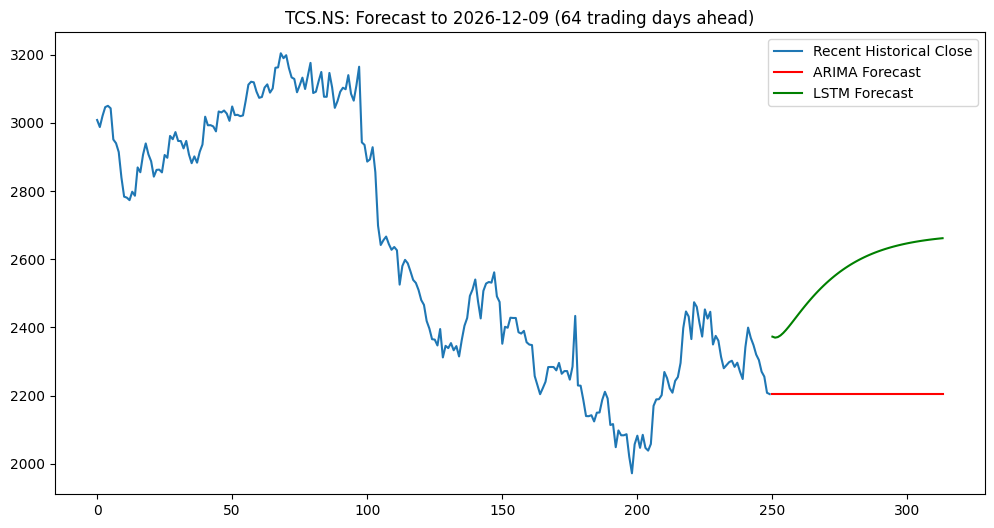

In [17]:
check_ticker = list(COMPANIES.values())[0]
r = results[check_ticker]

safe_name = check_ticker.replace(".", "_")
arima_fit = pickle.load(open(os.path.join(MODELS_DIR, f"arima_{safe_name}.pkl"), "rb"))
lstm_model = load_model(os.path.join(MODELS_DIR, f"lstm_{safe_name}.keras"))
scaler = pickle.load(open(os.path.join(MODELS_DIR, f"scaler_{safe_name}.pkl"), "rb"))

close = r["close_series"]
last_date = r["last_date"]
target_date = last_date + pd.Timedelta(days=90)

arima_dates, arima_preds = forecast_arima_to_date(arima_fit, last_date, target_date)

last_window_scaled = scaler.transform(close.values[-60:].reshape(-1, 1))
lstm_dates, lstm_preds = forecast_lstm_to_date(lstm_model, scaler, last_window_scaled, last_date, target_date)

plt.figure(figsize=(12, 6))
plt.plot(close.values[-250:], label="Recent Historical Close")
offset = len(close.values[-250:])
plt.plot(range(offset, offset + len(arima_preds)), arima_preds, label="ARIMA Forecast", color="red")
plt.plot(range(offset, offset + len(lstm_preds)), lstm_preds, label="LSTM Forecast", color="green")
plt.title(f"{check_ticker}: Forecast to {target_date.date()} ({len(arima_dates)} trading days ahead)")
plt.legend()
plt.show()


In [18]:
def load_company_models(ticker: str):
    safe_name = ticker.replace(".", "_")
    arima_fit = pickle.load(open(os.path.join(MODELS_DIR, f"arima_{safe_name}.pkl"), "rb"))
    lstm_model = load_model(os.path.join(MODELS_DIR, f"lstm_{safe_name}.keras"))
    scaler = pickle.load(open(os.path.join(MODELS_DIR, f"scaler_{safe_name}.pkl"), "rb"))
    return arima_fit, lstm_model, scaler

# Example:
# arima_fit, lstm_model, scaler = load_company_models("HDFCBANK.NS")


In [20]:
# List everything that got saved, to confirm all 10 companies x 3 files are present
import glob
saved_files = sorted(glob.glob(os.path.join(MODELS_DIR, "*")))
print(f"Total files saved: {len(saved_files)}")
for f in saved_files:
    print(" -", f)


Total files saved: 31
 - models/arima_BHARTIARTL_NS.pkl
 - models/arima_HDFCBANK_NS.pkl
 - models/arima_HINDUNILVR_NS.pkl
 - models/arima_ICICIBANK_NS.pkl
 - models/arima_INFY_NS.pkl
 - models/arima_ITC_NS.pkl
 - models/arima_MARUTI_NS.pkl
 - models/arima_RELIANCE_NS.pkl
 - models/arima_SBIN_NS.pkl
 - models/arima_TCS_NS.pkl
 - models/lstm_BHARTIARTL_NS.keras
 - models/lstm_HDFCBANK_NS.keras
 - models/lstm_HINDUNILVR_NS.keras
 - models/lstm_ICICIBANK_NS.keras
 - models/lstm_INFY_NS.keras
 - models/lstm_ITC_NS.keras
 - models/lstm_MARUTI_NS.keras
 - models/lstm_RELIANCE_NS.keras
 - models/lstm_SBIN_NS.keras
 - models/lstm_TCS_NS.keras
 - models/model_comparison_summary.csv
 - models/scaler_BHARTIARTL_NS.pkl
 - models/scaler_HDFCBANK_NS.pkl
 - models/scaler_HINDUNILVR_NS.pkl
 - models/scaler_ICICIBANK_NS.pkl
 - models/scaler_INFY_NS.pkl
 - models/scaler_ITC_NS.pkl
 - models/scaler_MARUTI_NS.pkl
 - models/scaler_RELIANCE_NS.pkl
 - models/scaler_SBIN_NS.pkl
 - models/scaler_TCS_NS.pkl


[*********************100%***********************]  1 of 1 completed


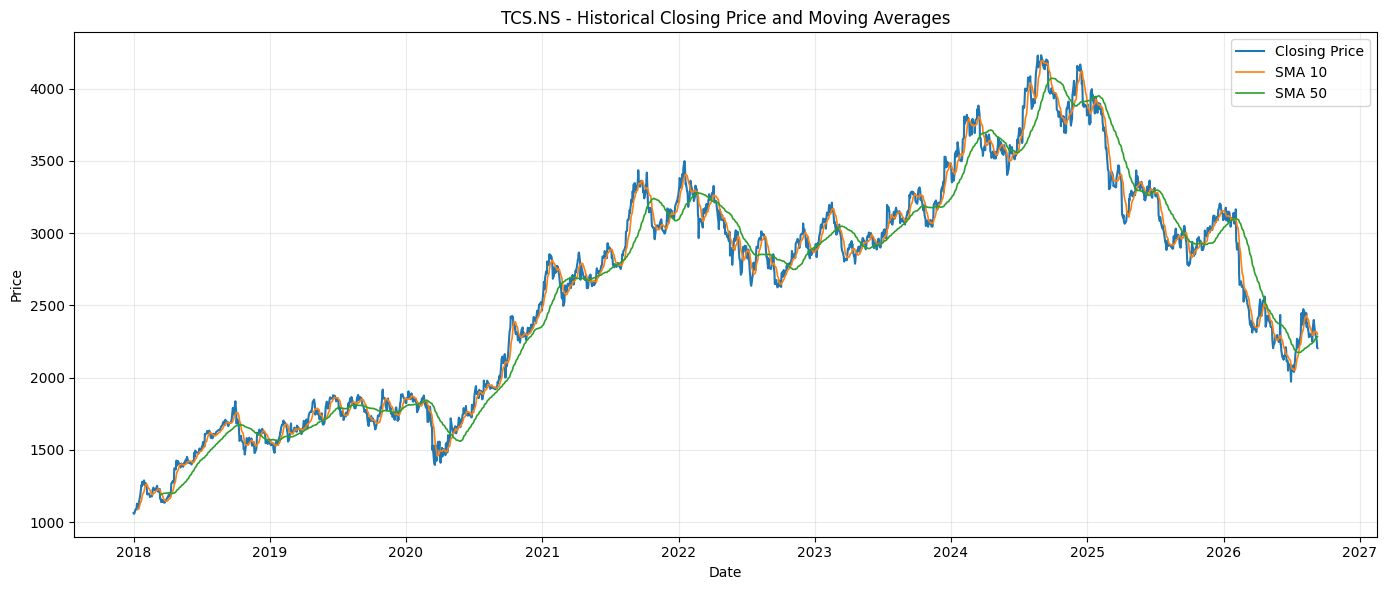

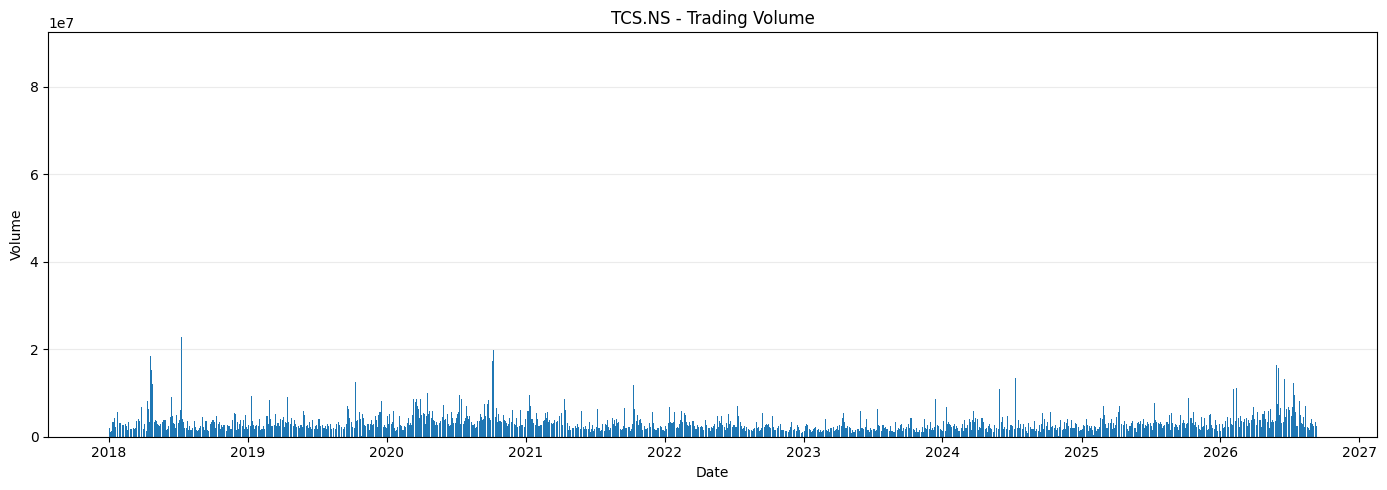

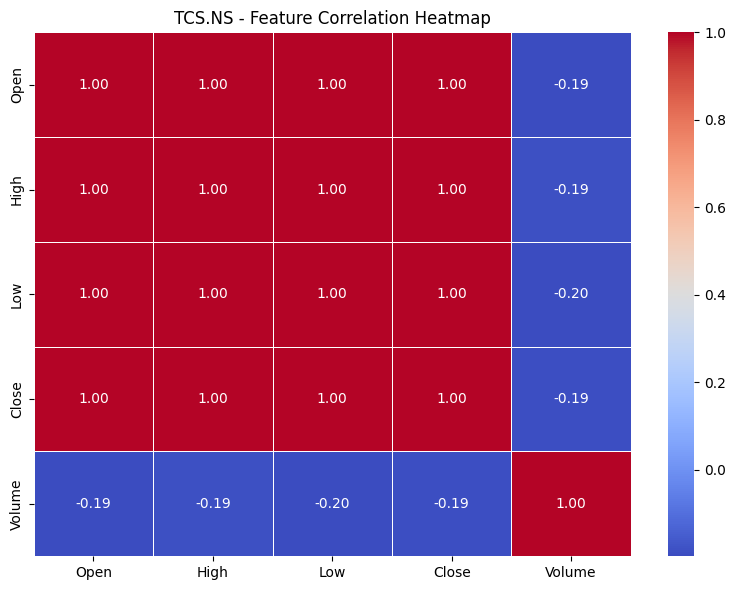

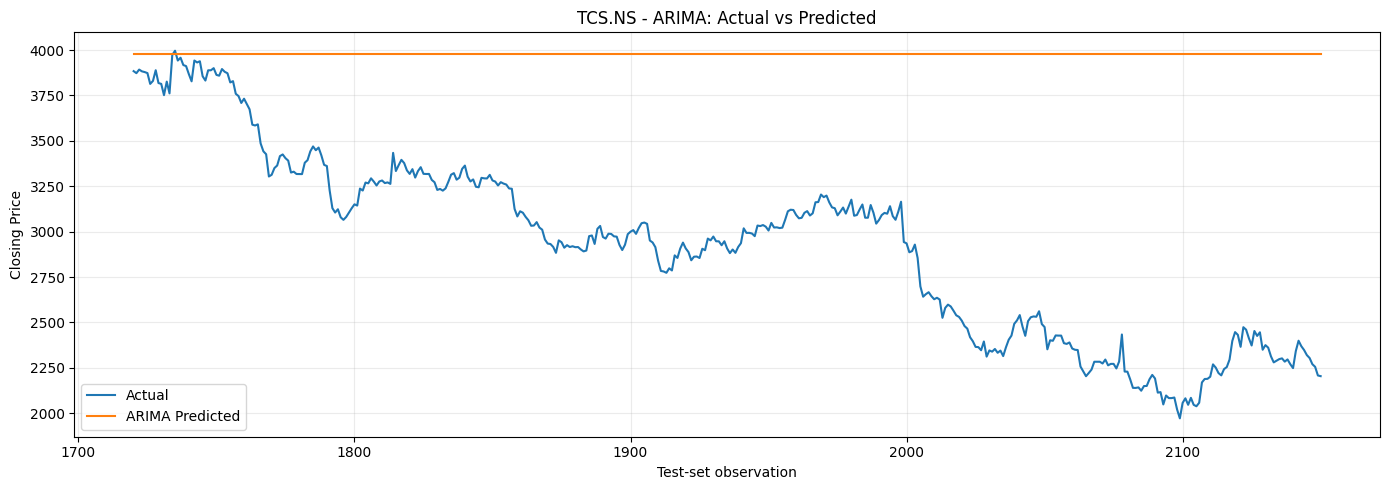

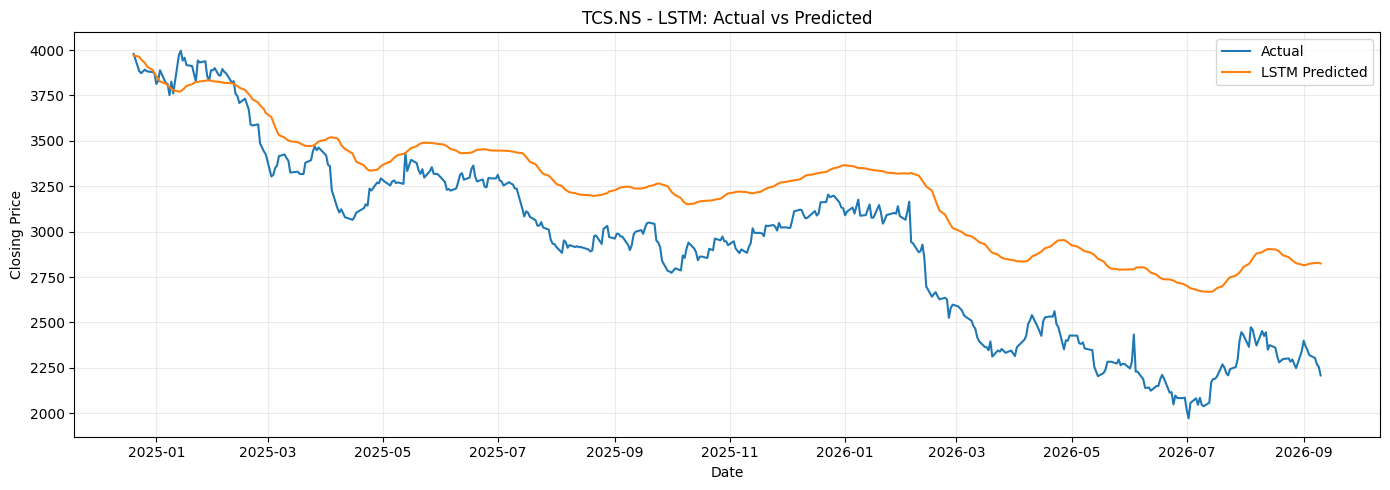

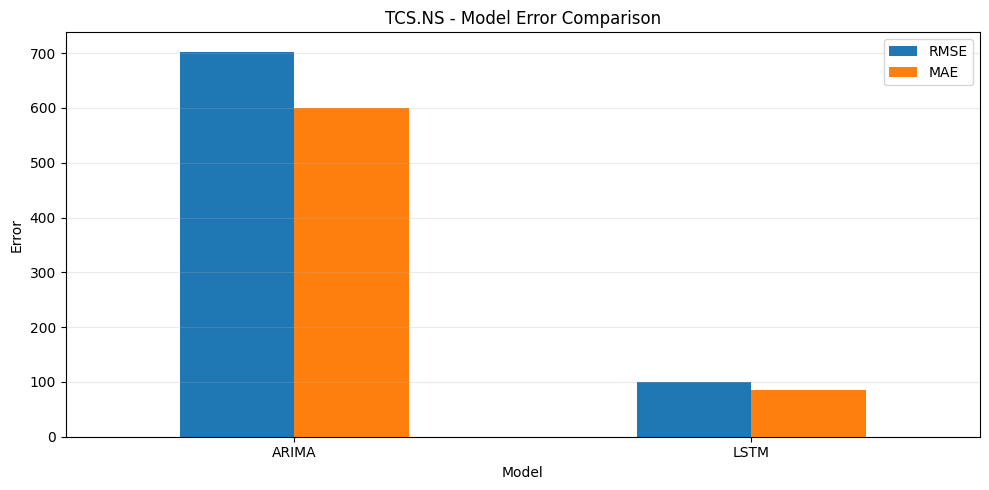

,Model,RMSE,MAE,MAPE (%)
0,ARIMA,702.95,600.27,24.79
1,LSTM,100.33,85.05,3.35


In [21]:
# =========================
# Visualization section
# =========================

import seaborn as sns
from sklearn.metrics import mean_squared_error

viz_ticker = check_ticker
viz_df = fetch_data(viz_ticker)

# Moving averages
viz_df["SMA_10"] = viz_df["Close"].rolling(10).mean()
viz_df["SMA_50"] = viz_df["Close"].rolling(50).mean()

# ---------------------------------------------------------
# 1. Historical Closing Price + Moving Averages
# ---------------------------------------------------------
plt.figure(figsize=(14, 6))
plt.plot(viz_df["Date"], viz_df["Close"], label="Closing Price", linewidth=1.5)
plt.plot(viz_df["Date"], viz_df["SMA_10"], label="SMA 10", linewidth=1.2)
plt.plot(viz_df["Date"], viz_df["SMA_50"], label="SMA 50", linewidth=1.2)
plt.title(f"{viz_ticker} - Historical Closing Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. Trading Volume
# ---------------------------------------------------------
plt.figure(figsize=(14, 5))
plt.bar(viz_df["Date"], viz_df["Volume"], width=2)
plt.title(f"{viz_ticker} - Trading Volume")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. Correlation Heatmap
# ---------------------------------------------------------
corr_cols = ["Open", "High", "Low", "Close", "Volume"]
plt.figure(figsize=(8, 6))
sns.heatmap(
    viz_df[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)
plt.title(f"{viz_ticker} - Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 4. Actual vs Predicted values on the test set
# ---------------------------------------------------------
# Recreate the 80/20 split used during training.
viz_train_size = int(len(viz_df) * 0.8)
viz_close = viz_df["Close"]

# ARIMA test prediction
viz_train_close = viz_close.iloc[:viz_train_size]
viz_test_close = viz_close.iloc[viz_train_size:]
viz_arima_order = r["arima_order"]

viz_arima_eval_fit = ARIMA(viz_train_close, order=viz_arima_order).fit()
viz_arima_test_pred = viz_arima_eval_fit.get_forecast(
    steps=len(viz_test_close)
).predicted_mean.values

# LSTM test prediction
viz_values = viz_close.values.reshape(-1, 1)
viz_scaler = MinMaxScaler(feature_range=(0, 1))
viz_scaler.fit(viz_values[:viz_train_size])
viz_scaled_all = viz_scaler.transform(viz_values)

viz_X, viz_y = make_sequences(viz_scaled_all, time_step=60)
viz_X = viz_X.reshape(viz_X.shape[0], viz_X.shape[1], 1)
viz_split_at = max(viz_train_size - 60 - 1, 1)

viz_X_test = viz_X[viz_split_at:]
viz_y_test = viz_y[viz_split_at:]

viz_lstm_test_pred = scaler.inverse_transform(
    lstm_model.predict(viz_X_test, verbose=0)
).flatten()
viz_lstm_test_actual = viz_scaler.inverse_transform(
    viz_y_test.reshape(-1, 1)
).flatten()

# Plot ARIMA
plt.figure(figsize=(14, 5))
plt.plot(viz_test_close.index, viz_test_close.values, label="Actual")
plt.plot(viz_test_close.index, viz_arima_test_pred, label="ARIMA Predicted")
plt.title(f"{viz_ticker} - ARIMA: Actual vs Predicted")
plt.xlabel("Test-set observation")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Plot LSTM
lstm_dates = viz_df["Date"].iloc[viz_train_size:].reset_index(drop=True)
plt.figure(figsize=(14, 5))
plt.plot(lstm_dates[:len(viz_lstm_test_actual)], viz_lstm_test_actual, label="Actual")
plt.plot(lstm_dates[:len(viz_lstm_test_pred)], viz_lstm_test_pred, label="LSTM Predicted")
plt.title(f"{viz_ticker} - LSTM: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. Model Error Comparison
# ---------------------------------------------------------
model_metrics = pd.DataFrame({
    "Model": ["ARIMA", "LSTM"],
    "RMSE": [r["arima_metrics"]["RMSE"], r["lstm_metrics"]["RMSE"]],
    "MAE": [r["arima_metrics"]["MAE"], r["lstm_metrics"]["MAE"]],
    "MAPE (%)": [r["arima_metrics"]["MAPE_%"], r["lstm_metrics"]["MAPE_%"]]
})

ax = model_metrics.set_index("Model")[["RMSE", "MAE"]].plot(
    kind="bar", figsize=(10, 5)
)
ax.set_title(f"{viz_ticker} - Model Error Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Error")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

model_metrics


In [22]:
!zip -r models.zip models/

  adding: models/ (stored 0%)
  adding: models/lstm_TCS_NS.keras (deflated 14%)
  adding: models/lstm_SBIN_NS.keras (deflated 14%)
  adding: models/scaler_HINDUNILVR_NS.pkl (deflated 33%)
  adding: models/scaler_ITC_NS.pkl (deflated 34%)
  adding: models/lstm_BHARTIARTL_NS.keras (deflated 14%)
  adding: models/lstm_ICICIBANK_NS.keras (deflated 14%)
  adding: models/scaler_TCS_NS.pkl (deflated 33%)
  adding: models/lstm_HDFCBANK_NS.keras (deflated 14%)
  adding: models/scaler_BHARTIARTL_NS.pkl (deflated 33%)
  adding: models/arima_ITC_NS.pkl (deflated 86%)
  adding: models/arima_SBIN_NS.pkl (deflated 82%)
  adding: models/scaler_INFY_NS.pkl (deflated 33%)
  adding: models/arima_ICICIBANK_NS.pkl (deflated 51%)
  adding: models/scaler_HDFCBANK_NS.pkl (deflated 34%)
  adding: models/scaler_MARUTI_NS.pkl (deflated 33%)
  adding: models/scaler_RELIANCE_NS.pkl (deflated 33%)
  adding: models/arima_HDFCBANK_NS.pkl (deflated 80%)
  adding: models/arima_MARUTI_NS.pkl (deflated 82%)
  adding: mod

In [23]:
from google.colab import files

files.download("models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>